# 04 — Perceived authenticity in recipe reviews

**Question:** *Do the recipes whose ingredients are most typical of their cuisine also get called "authentic" by the people who cook them?*

Before settling on this pipeline, we tested three simpler baselines—dictionary lookup, KWIC rules, and TF-IDF—and none worked reliably (see Section 9): it is hard to distinguish the many ways reviewers express authenticity and build a simple filter that catches real endorsements (like *"my Lebanese love said this is the way lentil soup is made"*) without also flagging incidental uses (like *"I used Traditional Ragu sauce"*).

Here are the steps we took instead:

1. **Word2Vec filter** — expand an authenticity lexicon following Le et al. (2022) and keep candidate reviews mentioning both an authenticity term and a recipe attribute.
2. **Pretrained embeddings (`gte-small`)** — embed each candidate review and measure cosine similarity to 6 authenticity anchor queries from Le et al. (2022).
3. **Clause flags + Logistic Regression** — combine the 6 similarities with 4 KWIC negation/wording flags and validate on hand-labeled train and test splits.
4. **Corpus scoring** — classify all 7,281 filtered reviews and aggregate endorsements to recipe level.
5. **Network comparison** — join with the ingredient-network scores (`network_recipe_distinctiveness_full.csv`) and test the link with within-cuisine shuffles and confounder checks.


## 0. Setup and data


In [1]:
from pathlib import Path
import html
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import spearmanr

# Resolve repository root whether run from repo root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "processed"
W2V_DIR = DATA / "recipe_word2vec"
MODEL_DIR = W2V_DIR / "full_review_training100" / "full_text_reduced_questions"
SHARE_DIR = DATA / "authenticity_shareable"
FIG_DIR = ROOT / "figures"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

recipes = pd.read_csv(DATA / "recipes.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
print(f"Loaded {len(recipes):,} recipes and {len(reviews):,} cleaned reviews across {recipes['cuisine'].nunique()} cuisines.")


Loaded 26,727 recipes and 132,744 cleaned reviews across 9 cuisines.


## 1. Word2Vec vocabulary filter

Following Le et al. (2022, *How consumers perceive authenticity in restaurants: A study of online reviews*), we trained Word2Vec on all 132,744 cleaned Food.com reviews (`docs/recipe_word2vec.md`) to expand a seed list of authenticity words and recipe attributes (`lexicon.csv`). We keep only reviews where an authenticity term and a recipe attribute appear in the same sentence, narrowing the corpus 18× to **7,281 candidate reviews (5.48%)** across **4,295 recipes**.


In [2]:
lexicon = pd.read_csv(W2V_DIR / "lexicon.csv")
print("Stage-1 Word2Vec lexicon summary (seed vs. Word2Vec-added terms):")
display(lexicon.groupby(["category", "source"]).size().unstack(fill_value=0))
print("Word2Vec-added authenticity terms:", sorted(lexicon.query("category == 'authenticity' and source == 'word2vec'")["token"].tolist()))

neighbors = pd.read_csv(W2V_DIR / "neighbors.csv")
print("\nTop Word2Vec neighbors of 'authentic' learned on Food.com reviews:")
display(neighbors.query("seed == 'authentic'").head(6)[["seed", "rank", "neighbor", "cosine"]])

filtered_reviews = pd.read_csv(W2V_DIR / "dictionary_matched_full_reviews.csv")
print(f"Stage-1 Word2Vec screen: {len(filtered_reviews):,} candidate reviews "
      f"({len(filtered_reviews)/len(reviews):.2%} of corpus) across {filtered_reviews['recipe_id'].nunique():,} recipes.")


Stage-1 Word2Vec lexicon summary (seed vs. Word2Vec-added terms):


source,seed,word2vec
category,,
authenticity,88,10
dish,13,57
ingredient,10,33
origin,17,37
preparation,6,19
reference,5,23
sensory,4,18


Word2Vec-added authenticity terms: ['authenic', 'authentically', 'clone', 'copycat', 'duplicate', 'homeade', 'imitate', 'recreate', 'reproduce', 'speciality']

Top Word2Vec neighbors of 'authentic' learned on Food.com reviews:


,seed,rank,neighbor,cosine
42,authentic,1.0,authentically,0.758983
43,authentic,2.0,authenic,0.696370
44,authentic,3.0,comparable,0.687096
45,authentic,4.0,americanized,0.678816
46,authentic,5.0,acquired,0.678674
47,authentic,6.0,genuine,0.655347


Stage-1 Word2Vec screen: 7,281 candidate reviews (5.48% of corpus) across 4,295 recipes.


## 2. Embedding model and biases

We encode each candidate review with **`gte-small`** (33M parameters, 384 dimensions), a pretrained sentence-transformer built on the same contextual BERT-style architecture covered in Week 7 (like MiniLM), but trained with multi-stage contrastive learning for sharper semantic similarity while staying fast on CPU.

Three biases apply here. First, `gte-small` is pretrained on general English web and academic text rather than cooking forums, so it reflects mainstream English associations around "authentic" and can misread brand names (*"Traditional Ragu"*). Second, as a bi-encoder, it embeds the review and each query separately, so it needs explicit wording flags for negation and contrast (*"supposed to be authentic, but..."*). Third, Food.com (1999–2018) is mostly North American and English-speaking, so this measures *Food.com home cooks' perceived authenticity*, not local culinary history.


## 3. Queries, flags, and classifier

Le et al. (2022, Fig. 1, p. 8) organize perceived authenticity into concrete cues—connection to remembered people/places, conformity to or deviation from a tradition, inherent qualities, and self-connectedness:


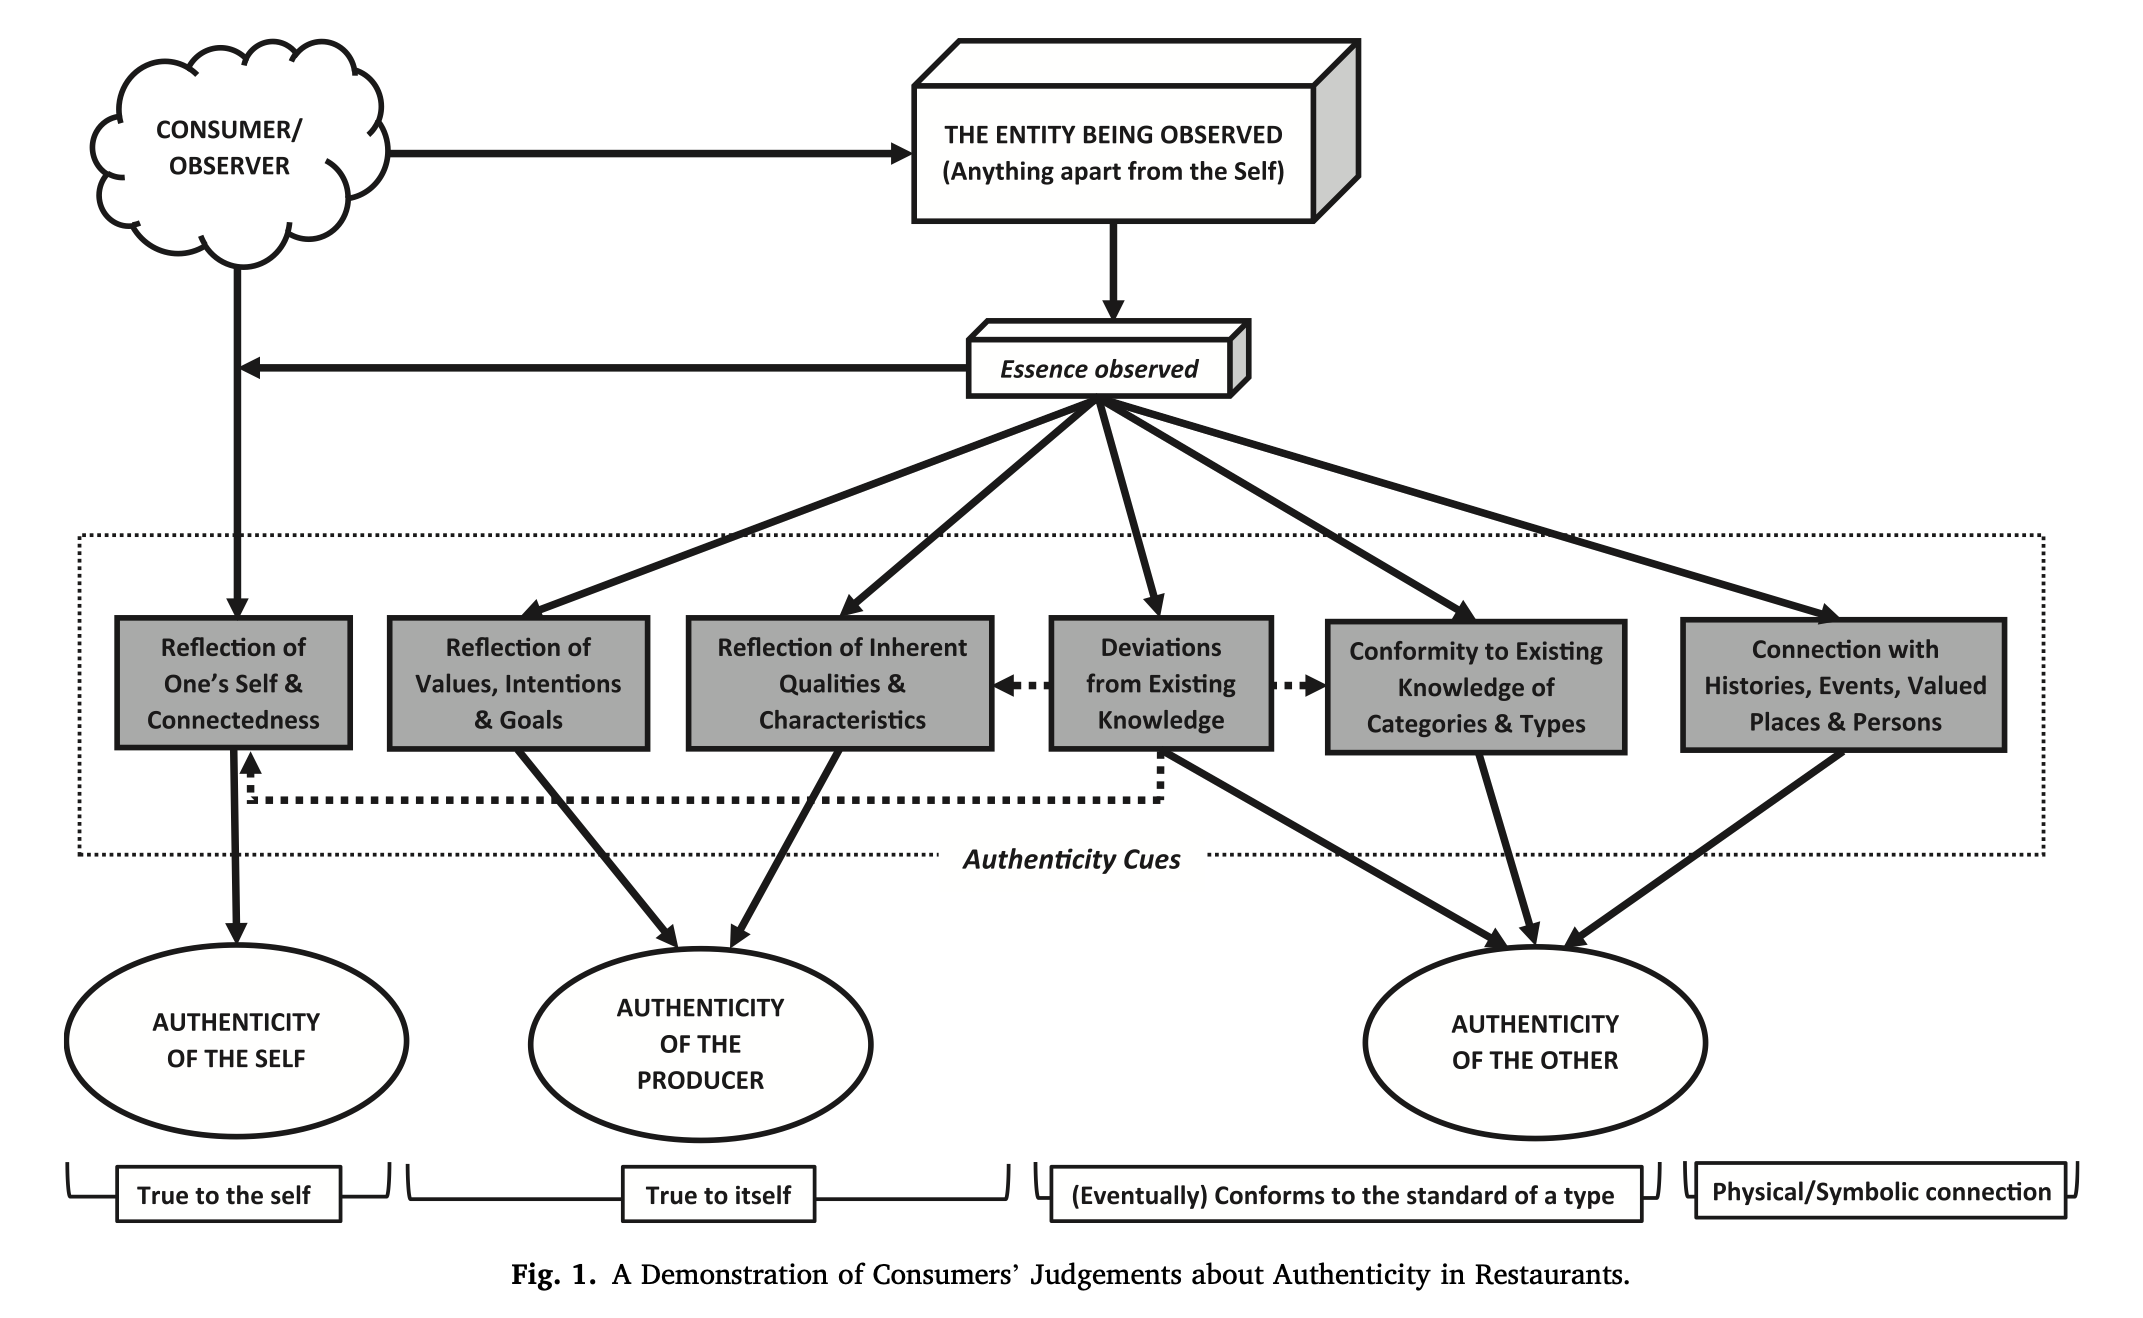

In [3]:
page8_img = FIG_DIR / "le2022_page8_themes.png"
if page8_img.exists():
    display(Image(filename=str(page8_img), width=780))
else:
    print("Note: figures/le2022_page8_themes.png not found.")


We turn those cues into **6 short anchor queries** and represent each review by **10 features** fed into a regularized **Logistic Regression**:
- **6 cosine similarities** between the review's `gte-small` embedding and the 6 queries below.
- **4 clause-level KWIC flags:** affirmative authenticity cue without negation/change, negated cue (*"not authentic"*), suggested change (*"more authentic"*), and resemblance phrasing (*"just like"*).


In [4]:
pd.set_option("display.max_colwidth", None)
queries = pd.read_csv(W2V_DIR / "gte_single_queries.csv")
selected_themes = ["connection", "conformity", "dish_target", "affirmation", "deviation", "self_connectedness"]
print("6 anchor queries (embedded with gte-small):")
display(queries[queries["theme"].isin(selected_themes)].reset_index(drop=True))

kwic_checks = pd.DataFrame([
    {"flag": "1. Affirmative cue", "pattern / rule": "authentic*, traditional*, genuine, real thing, real deal — with NO negation in the 7 words before and NO modification cue in the clause"},
    {"flag": "2. Negated cue", "pattern / rule": "Cue preceded within 7 words by: not, never, no, hardly, lack(s/ed), without, anything but, far from, n't"},
    {"flag": "3. Modification cue", "pattern / rule": "Cue in same clause as: more authentic, instead of, substitut*, would, could, should, next time, to make it more"},
    {"flag": "4. Resemblance phrase", "pattern / rule": "just like, exactly like, reminds me of, taste(s) like the original, close to the original — with NO negation in the clause"},
])
print("\n4 clause-level KWIC checks (split on . ! ? ; and 'but'):")
display(kwic_checks)


6 anchor queries (embedded with gte-small):


,theme,query
0,connection,This recipe resembles food made by a remembered person or served at a remembered place or event.
1,conformity,The reviewer judges whether the dish matches the expected regional or traditional version.
2,deviation,The reviewer describes a departure from the expected dish or traditional way of making it.
3,self_connectedness,"This food connects me with my upbringing, home, identity or family traditions."
4,dish_target,"The reviewer judges the posted dish against a family, restaurant or culinary tradition."
5,affirmation,The reviewer confirms that the posted dish matches a remembered or authentic version.



4 clause-level KWIC checks (split on . ! ? ; and 'but'):


,flag,pattern / rule
0,1. Affirmative cue,"authentic*, traditional*, genuine, real thing, real deal — with NO negation in the 7 words before and NO modification cue in the clause"
1,2. Negated cue,"Cue preceded within 7 words by: not, never, no, hardly, lack(s/ed), without, anything but, far from, n't"
2,3. Modification cue,"Cue in same clause as: more authentic, instead of, substitut*, would, could, should, next time, to make it more"
3,4. Resemblance phrase,"just like, exactly like, reminds me of, taste(s) like the original, close to the original — with NO negation in the clause"


## 4. Train and test evaluation

We evaluate on two clean labeled splits in `data/processed/authenticity_shareable/`: **`train_100.csv`** (100 reviews, 33 positives, 5-fold CV) and **`test_100.csv`** (100 unseen reviews, 22 positives).


In [5]:
train_df = pd.read_csv(SHARE_DIR / "train_100.csv")
test_df = pd.read_csv(SHARE_DIR / "test_100.csv")

def summarize_split(name, df):
    y = df["manual_label"].astype(bool)
    p = df["model_prediction"].astype(bool)
    tp, fp, fn, tn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum()), int((~y & ~p).sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {
        "split": name, "n": len(df), "manual_pos": int(y.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": round(prec, 3), "recall": round(rec, 3), "F1": round(f1, 3),
    }

perf = pd.DataFrame([
    summarize_split("train_100 (5-fold CV)", train_df),
    summarize_split("test_100 (unseen held-out)", test_df),
])
display(perf)

print("\nSample of manually labeled TRAINING reviews (3 positive, 3 negative):")
tr_sample = pd.concat([
    train_df[train_df["manual_label"].astype(bool)].head(3),
    train_df[~train_df["manual_label"].astype(bool)].head(3),
])[["recipe_id", "manual_label", "model_prediction", "full_review"]].copy()
tr_sample["full_review"] = tr_sample["full_review"].map(lambda s: " ".join(html.unescape(s).split())[:130] + "...")
display(tr_sample)

print("\nSample of manually labeled HELD-OUT TEST reviews (3 positive, 3 negative):")
te_sample = pd.concat([
    test_df[test_df["manual_label"].astype(bool)].head(3),
    test_df[~test_df["manual_label"].astype(bool)].head(3),
])[["recipe_id", "manual_label", "model_prediction", "full_review"]].copy()
te_sample["full_review"] = te_sample["full_review"].map(lambda s: " ".join(html.unescape(s).split())[:130] + "...")
display(te_sample)


,split,n,manual_pos,TP,FP,FN,TN,precision,recall,F1
0,train_100 (5-fold CV),100,33,18,5,15,62,0.783,0.545,0.643
1,test_100 (unseen held-out),100,22,16,1,6,77,0.941,0.727,0.821



Sample of manually labeled TRAINING reviews (3 positive, 3 negative):


,recipe_id,manual_label,model_prediction,full_review
4,24201,1,False,"As a French Acadian in northern Aroostook County, Maine, we served these warm with Homemade Baked Beans on a Saturday night. We'd ..."
8,68955,1,True,"I live in Tokyo now and this recipe is authentic and delicious. And, I'm grateful for the translation. Trust the recipe! I actuall..."
10,248495,1,True,"Terrific! Even in the States, this type of cheese is expensive and I rarely buy it. Here, on the other side of the world, it's lik..."
0,38298,0,False,I made a huge 13 quart batch of this for a group.It was a huge hit! <br/>the only thing I did different was that I used real bacon...
1,22782,0,False,"An excellent recipe! When we have spaghetti at our house this is what I make every time. This recipe with homemade pasta, homemade..."
2,58122,0,False,This is a great recipe. It's so simple to make and it is definitely delicious. I'm not real skilled in the kitchen and this recipe...



Sample of manually labeled HELD-OUT TEST reviews (3 positive, 3 negative):


,recipe_id,manual_label,model_prediction,full_review
0,166030,1,True,The perfect mixture for that traditional taco taste. No need to buy that packaged stuff. I used it for recipe #160564 and it was g...
1,47453,1,True,Thank you for putting up an authentic recipe!...
7,142306,1,True,This is an Authentic recipe that I and my husband use. We're from Michocan Mexico. But we prefer Queso Fresco crumbled on top with...
2,8745,0,False,wonderful I Dont' think i will ever make original enchiladas again. We are died in the wool Texans so everyone turned tier noses u...
3,31717,0,False,"I halved this recipe for my smaller crock pot. I also veganized it (using tvp for the ground beef and made my own veggie ""beefish""..."
4,88348,0,False,I made a vegetarian version of the soup by replacing the chicken with beans and a bit of chopped veggies. Even with the substituti...


## 5. Scoring all filtered reviews

On the 100 unseen test reviews, the model reaches **94.1% precision (16/17)** and **72.7% recall (16/22; F1 = 0.821)**. Below we summarize its predictions across all **7,281** Word2Vec-filtered reviews.


Reviews classified: 7,281
  Endorsed reviews:     1,143 (15.7%)
  Non-endorsed reviews: 6,138 (84.3%)
Recipes covered:    4,295
  Endorsed recipes:     839 (19.5%)
  Non-endorsed recipes: 3,456 (80.5%)


,matched_reviews,endorsed_reviews,matched_recipes,review_endorsement_rate
cuisine,,,,
japanese,190,41,130,0.216
greek,564,119,345,0.211
indian,559,111,388,0.199
middle-eastern,476,93,342,0.195
chinese,517,100,293,0.193
thai,302,48,205,0.159
mexican,2028,317,1142,0.156
italian,2224,278,1151,0.125
french,421,36,299,0.086


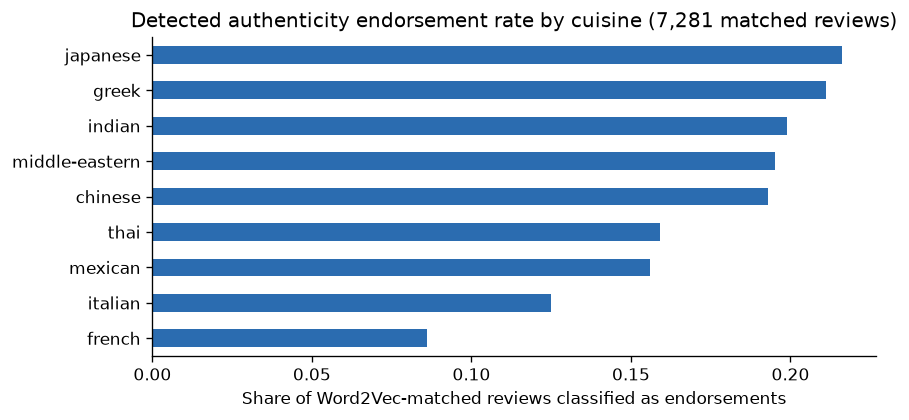

In [6]:
pred_reviews = pd.read_csv(MODEL_DIR / "broad_review_predictions.csv")
n_pos_rev = int(pred_reviews["predicted_endorsement"].sum())
n_pos_rec = int(pred_reviews.loc[pred_reviews["predicted_endorsement"], "recipe_id"].nunique())
n_tot_rec = int(pred_reviews["recipe_id"].nunique())

print(f"Reviews classified: {len(pred_reviews):,}")
print(f"  Endorsed reviews:     {n_pos_rev:,} ({n_pos_rev/len(pred_reviews):.1%})")
print(f"  Non-endorsed reviews: {len(pred_reviews) - n_pos_rev:,} ({1 - n_pos_rev/len(pred_reviews):.1%})")
print(f"Recipes covered:    {n_tot_rec:,}")
print(f"  Endorsed recipes:     {n_pos_rec:,} ({n_pos_rec/n_tot_rec:.1%})")
print(f"  Non-endorsed recipes: {n_tot_rec - n_pos_rec:,} ({1 - n_pos_rec/n_tot_rec:.1%})")

by_cuisine = (
    pred_reviews.groupby("cuisine")
    .agg(
        matched_reviews=("review_id", "size"),
        endorsed_reviews=("predicted_endorsement", "sum"),
        matched_recipes=("recipe_id", "nunique"),
    )
    .assign(review_endorsement_rate=lambda d: (d["endorsed_reviews"] / d["matched_reviews"]).round(3))
    .sort_values("review_endorsement_rate", ascending=False)
)
display(by_cuisine)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
by_cuisine["review_endorsement_rate"].sort_values().plot.barh(ax=ax, color="#2b6cb0")
ax.set_xlabel("Share of Word2Vec-matched reviews classified as endorsements")
ax.set_ylabel("")
ax.set_title("Detected authenticity endorsement rate by cuisine (7,281 matched reviews)")
plt.tight_layout()
plt.show()


## 6. Comparison with the ingredient network

We join recipe-level endorsements with the ingredient-network scores from `03_network_analysis.ipynb` (`network_recipe_distinctiveness_full.csv`): `ingredient_distinctiveness` (*what* single ingredients), `pair_distinctiveness` (*which* pairs), and `pairing_score` (*how* pairs co-occur above chance). Below we check endorsement rates across within-cuisine quartiles of `pairing_score`, per-cuisine correlations, and 2,000-permutation shuffle tests controlling for cuisine, dish type, recipe size, and review count.


,pairing_q,recipes,endorsed,endorsement_rate
0,Q1 (lowest 25%),1073,158,14.7%
1,Q2,1067,187,17.5%
2,Q3,1067,216,20.2%
3,Q4 (highest 25%),1068,277,25.9%


Top 10% vs Bottom 10% of pairing_score: 13.2% -> 25.6% (1.93x higher endorsement rate)


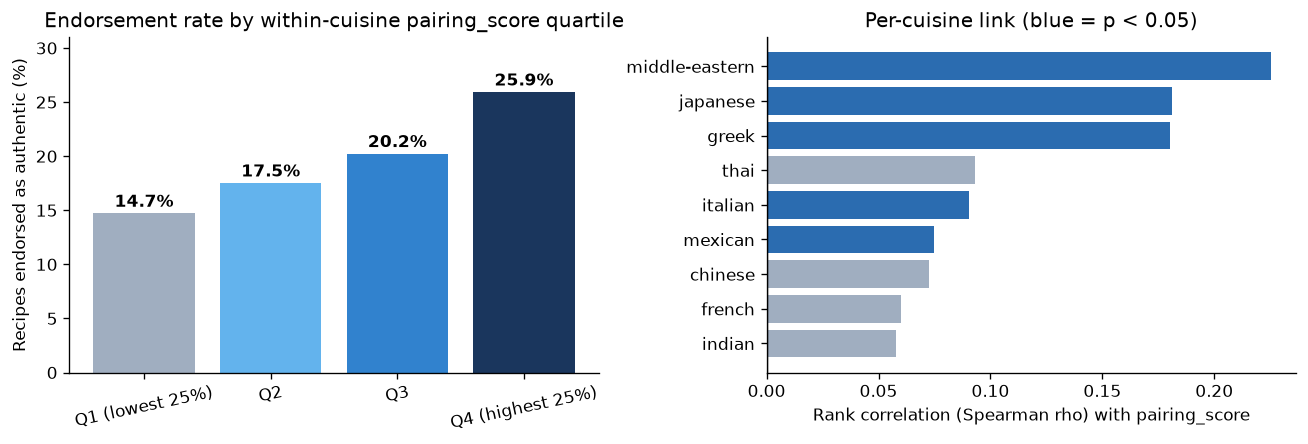

In [7]:
# Same conservative title classifier as scripts/recipe_type_analysis.py (inlined to keep Jupyter's inline plot backend)
def classify_title(title: str) -> str:
    t = title.lower()
    if re.search(r"\b(?:smoothie|milkshake|lassi)\b", re.sub(r"\b(?:shrimp|prawn|ceviche)\s+cocktail\b", "", t)):
        return "drink"
    dt = re.sub(r"\b(?:salmon|crab|fish|scallion|rice)\s+cakes?\b", "", t)
    if re.search(r"\b(?:desserts?|cakes?|cupcakes?|cheesecakes?|cookies?|brownies?|blondies?|puddings?|custards?|ice\s+cream|sorbets?|gelato|fudge|mousse|tiramisu|baklava|panna\s+cotta|sweet\s+rolls?|parfaits?|cobblers?|fruit\s+tarts?|chocolate\s+tarts?|apple\s+pies?|pumpkin\s+pies?|pecan\s+pies?)\b", dt):
        return "dessert/sweet"
    dr = re.sub(r"\b(?:shrimp|prawn|ceviche)\s+cocktail\b|\bmargarita\s+(?:fajitas?|chicken|grill)\b", "", t)
    if re.search(r"\b(?:cocktail|margarita|martini|mojito|sangria|lemonade|iced\s+(?:tea|coffee)|hot\s+chocolate|punch|mocktail|cosmopolitan|kir\s+royal|liqueur|shooter)\b", dr):
        return "drink"
    return "other"

joined = pd.read_csv(MODEL_DIR / "giulia_recipe_join.csv")
max_score = pred_reviews.groupby("recipe_id")["score"].max().rename("max_score")
m = (
    joined[joined["matched_reviews"] > 0]
    .merge(recipes[["recipe_id", "name", "n_ingredients"]], on="recipe_id", how="left")
    .merge(max_score, on="recipe_id", how="left")
    .dropna(subset=["pairing_score"])
    .reset_index(drop=True)
)
m["y"] = m["predicted_endorsement"].astype(int)
m["recipe_type"] = m["name"].fillna("").map(classify_title)
m["size_bin"] = pd.cut(m["n_ingredients"], bins=[0, 6, 9, 12, 100], labels=["<=6", "7-9", "10-12", "13+"])
m["pairing_q"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest 25%)", "Q2", "Q3", "Q4 (highest 25%)"])
)
m["pairing_d"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
)

# Quartile & top-vs-bottom decile summary
q_df = m.groupby("pairing_q", observed=False).agg(
    recipes=("recipe_id", "size"), endorsed=("y", "sum"), endorsement_rate=("y", "mean")
).reset_index()
display(q_df.assign(endorsement_rate=lambda d: d["endorsement_rate"].map("{:.1%}".format)))

d_rates = m.groupby("pairing_d", observed=False)["y"].mean()
print(f"Top 10% vs Bottom 10% of pairing_score: {d_rates.iloc[0]:.1%} -> {d_rates.iloc[-1]:.1%} "
      f"({d_rates.iloc[-1]/d_rates.iloc[0]:.2f}x higher endorsement rate)")

# Plot quartiles & per-cuisine correlations side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(q_df["pairing_q"], q_df["endorsement_rate"] * 100, color=["#a0aec0", "#63b3ed", "#3182ce", "#1a365d"])
for i, v in enumerate(q_df["endorsement_rate"] * 100):
    ax1.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontweight="bold")
ax1.set_ylim(0, 31)
ax1.set_ylabel("Recipes endorsed as authentic (%)")
ax1.set_title("Endorsement rate by within-cuisine pairing_score quartile")
ax1.tick_params(axis="x", rotation=12)

c_rows = []
for c, g in m.groupby("cuisine"):
    r, p = spearmanr(g["y"], g["pairing_score"])
    c_rows.append({"cuisine": c, "n": len(g), "endorsed": int(g["y"].sum()), "rho": r, "p": p})
c_df = pd.DataFrame(c_rows).sort_values("rho")
colors = ["#2b6cb0" if p < 0.05 else "#a0aec0" for p in c_df["p"]]
ax2.barh(c_df["cuisine"], c_df["rho"], color=colors)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Rank correlation (Spearman rho) with pairing_score")
ax2.set_title("Per-cuisine link (blue = p < 0.05)")
plt.tight_layout()
plt.show()


In [8]:
# Week 2 within-cuisine / stratified label-shuffle null tests (2,000 permutations)
def shuffle_test(df, y_col, x_col, strata, n_perm=2000, seed=42):
    sub = df[strata + [y_col, x_col]].dropna().reset_index(drop=True)
    y = sub[y_col].to_numpy(dtype=float)
    xr = pd.Series(sub[x_col].to_numpy(dtype=float)).rank().to_numpy()
    xc = xr - xr.mean()
    xn = np.linalg.norm(xc)
    def fast_rho(v):
        r = pd.Series(v).rank().to_numpy()
        rc = r - r.mean()
        return float(np.dot(rc, xc) / (np.linalg.norm(rc) * xn))
    obs = fast_rho(y)
    groups = [idx.to_numpy() for _, idx in sub.groupby(strata[0] if len(strata) == 1 else strata, observed=False).groups.items()]
    rng = np.random.default_rng(seed)
    null = np.empty(n_perm)
    perm = y.copy()
    for i in range(n_perm):
        for g in groups:
            perm[g] = rng.permutation(y[g])
        null[i] = fast_rho(perm)
    z = (obs - null.mean()) / null.std(ddof=1)
    emp_p = (1 + np.sum(np.abs(null - null.mean()) >= abs(obs - null.mean()))) / (n_perm + 1)
    return {"n": len(sub), "obs_rho": round(obs, 4), "null_mean": round(float(null.mean()), 4),
            "z_score": round(float(z), 2), "empirical_p": round(float(emp_p), 5)}

no_sd = m[~m["recipe_type"].isin(["dessert/sweet", "drink"])]
strict = no_sd[no_sd["matched_reviews"] == 1]

tests = [
    ("Single ingredients (ingredient_distinctiveness)", m, "y", "ingredient_distinctiveness", ["cuisine"]),
    ("Ingredient pairs (pair_distinctiveness)", m, "y", "pair_distinctiveness", ["cuisine"]),
    ("Pairing above chance (pairing_score)", m, "y", "pairing_score", ["cuisine"]),
    ("Robustness: continuous score (no cutoff)", m, "max_score", "pairing_score", ["cuisine"]),
    ("Robustness: excl. sweets/drinks, within cuisine x size", no_sd, "y", "pairing_score", ["cuisine", "size_bin"]),
    ("Robustness: excl. sweets/drinks + exactly 1 review", strict, "y", "pairing_score", ["cuisine", "size_bin"]),
]
shuf_table = pd.DataFrame([{"test": lbl, **shuffle_test(sub, yc, xc, st)} for lbl, sub, yc, xc, st in tests])
display(shuf_table)


,test,n,obs_rho,null_mean,z_score,empirical_p
0,Single ingredients (ingredient_distinctiveness),4275,0.0178,0.0095,0.59,0.53823
1,Ingredient pairs (pair_distinctiveness),4275,0.0439,0.0129,2.10,0.03898
2,Pairing above chance (pairing_score),4275,0.0896,-0.0101,6.80,0.00050
3,Robustness: continuous score (no cutoff),4275,0.0751,-0.0085,5.70,0.00050
4,"Robustness: excl. sweets/drinks, within cuisine x size",4084,0.0876,-0.0106,6.57,0.00050
5,Robustness: excl. sweets/drinks + exactly 1 review,3072,0.0645,-0.0098,4.41,0.00050


## 7. Considerations and conclusions

Across the **4,275 matched recipes**, listing cuisine-specific *single* ingredients (`ingredient_distinctiveness`) has almost no link with being called authentic, while characteristic ingredient *pairing* (`pairing_score`) shows a steady climb: endorsement rises from **14.7%** in the lowest quartile to **25.9%** in the highest quartile, and nearly doubles from **13.2% to 25.6%** between the bottom and top deciles. Because the overall rank correlation is modest ($
ho = 0.090$), the main doubt is whether this gap could be chance, an artifact of our yes/no cutoff, or a side effect of review volume, dish type, or recipe size.

Simple checks rule those doubts out. Shuffling authenticity labels within each cuisine 2,000 times never once reached the real `pairing_score` link (**$z = 6.80$, empirical $p = 0.0005$**), while single ingredients looked like chance ($z = 0.69$). Using the model's continuous score with no cutoff gives the same positive link ($
ho = 0.075, p < 10^{-6}$), dropping desserts and drinks barely changes it ($
ho = 0.088$), longer recipes actually have *lower* `pairing_score`, and holding **cuisine, dish type, recipe size, and review count** fixed at once (3,072 savory recipes with exactly 1 matched review) still yields **$z = 4.41$** (0 of 2,000 shuffles beat the data).

Our answer to the paper's question is therefore **yes, modestly, and specifically through *how* ingredients are paired rather than *which* single ingredients appear**. All nine cuisines lean positive—most clearly Middle Eastern, Japanese, Greek, Italian, and Mexican—showing that cooks recognize characteristic ingredient combinations above chance. At the same time, the modest size of $
ho pprox 0.09$ shows that ingredients are only part of perceived authenticity, leaving large room for technique, proportions, personal memories, and Food.com's North American audience.

## 8. Limitations and next steps

- **Stage-1 recall:** Purely implicit endorsements with no Word2Vec lexicon word (e.g., *"just like my grandmother made"*) sit outside the 7,281-review screen.
- **Validation size & agreement:** Test recall (`16/22`) is estimated on 100 unseen reviews; double-coding a subset with two human annotators would add inter-annotator agreement.
- **Criticism vs. neutrality:** Explicit denials (*"not authentic"*) are grouped with neutral mentions rather than modeled as a separate negative class.
- **Platform bias:** Food.com mostly reflects North American English-speaking home cooks, not local culinary tradition.
- **Potential improvements:** Running an instruction-tuned **LLM** across the 7,281 filtered reviews as a second-method check could recover missed implicit endorsements (*"Now THIS is real Italian gravy!"*) and cleanly separate endorsements, denials, and store-bought ingredient mentions.


## 9. Why simpler baselines failed

### 9.1 Dictionary lookup

Counting `"authentic"` or synonyms flags every occurrence regardless of meaning—including negations (*"not authentic"*), store-bought brands (*"Traditional Ragu"*), and generic praise (*"a real hit"*).


In [9]:
# Simple regex counts on the 132,744 cleaned reviews
reviews["text_clean"] = reviews["review"].fillna("").map(html.unescape)
terms = ["authentic", "traditional", "original", "real", "genuine"]
counts = []
for t in terms:
    hit = reviews["text_clean"].str.contains(rf"\b{t}\b", case=False, regex=True)
    counts.append({
        "term": t,
        "matching_reviews": int(hit.sum()),
        "share_of_reviews": f"{hit.mean():.2%}",
        "matching_recipes": int(reviews.loc[hit, "recipe_id"].nunique()),
    })
display(pd.DataFrame(counts))

# Concrete Food.com examples where naive dictionary lookup fails
bad_examples = [
    ("Store-bought ingredient ('Traditional')",
     reviews[reviews["text_clean"].str.contains(r"Traditional\s+Ragu", case=False, regex=True)].head(1)),
    ("Negation ('not authentic')",
     reviews[reviews["text_clean"].str.contains(r"not\s+authentic", case=False, regex=True)].head(1)),
    ("Generic intensifier ('real hit')",
     reviews[reviews["text_clean"].str.contains(r"\breal\s+hit\b", case=False, regex=True)].head(1)),
]
for label, sub in bad_examples:
    if len(sub):
        snippet = " ".join(sub.iloc[0]["text_clean"].split())[:220]
        print(f"[{label}] {snippet}...")


,term,matching_reviews,share_of_reviews,matching_recipes
0,authentic,1246,0.94%,861
1,traditional,744,0.56%,611
2,original,771,0.58%,614
3,real,2103,1.58%,1481
4,genuine,25,0.02%,25


[Store-bought ingredient ('Traditional')] Fantastic! I did, however, add store bought Traditional Ragu sauce to make it more saucy because that's my preference. It turned out excellent! This is a new favorite recipe! Thanks for posting this!...
[Negation ('not authentic')] Very close to the restaurants. HOWEVER!!! The special sauce...This recipe is WAY too complicated. As a former Chang's server (opened the first store in SC and worked there for over a year) - Simplify it. Although each se...
[Generic intensifier ('real hit')] I made these for my husbands birthday. They were a real hit. I did double the cabbage and used a little extra shrimp. Thanks for the recipe....


### 9.2 KWIC concordance

KWIC is useful for inspecting usage and catching simple local negations, but brittle as a classifier: *"Their recipe was supposed to be authentic, but these taste so much better"* puts `"authentic"` affirmatively next to `"recipe"`, even though it refers to a different recipe.


In [10]:
def kwic_samples(series, word="authentic", width=45, n=8, seed=42):
    pat = re.compile(rf"\b{word}\w*\b", re.I)
    rows = []
    for txt in series.sample(frac=1, random_state=seed):
        flat = " ".join(txt.split())
        m = pat.search(flat)
        if m:
            left = flat[max(0, m.start() - width):m.start()].rjust(width)
            mid = m.group(0)
            right = flat[m.end():m.end() + width]
            rows.append({"left_context": left, "keyword": mid, "right_context": right})
            if len(rows) >= n:
                break
    return pd.DataFrame(rows)

display(kwic_samples(reviews["text_clean"], word="authentic", n=8, seed=7))

# Real failure case from our held-out test set where KWIC sees 'authentic' affirmatively next to 'recipe'
te_raw = pd.read_csv(SHARE_DIR / "test_100.csv")
tricky = te_raw[te_raw["full_review"].str.contains("culinary school", case=False, na=False)]
if len(tricky):
    print("\nReal KWIC failure case (manual_label =", bool(tricky.iloc[0]["manual_label"]), "):")
    print(" ", " ".join(html.unescape(tricky.iloc[0]["full_review"]).split())[:260])


,left_context,keyword,right_context
0,ere with the aroma of these meatballs in the,authentic,sauce wafting from my kitchen I haven't eate
1,Loved this recipe. Used an,authentic,black bean with chili paste which was plenty
2,"Very easy to make, very",authentic,", tasted good, was able to impress my toughes"
3,n't have to wait to go back to Mexico to eat,authentic,guacamole. Thank you.
4,"This was delicious. I don't know how """,authentic,""" it is, but it did not really matter to us."
5,"and it worked beautifully. Served with the """,Authentic,"Itallian Meatballs""--#92095. This recipe is"
6,give some crispness. Your recipe looks more,authentic,", but this version was super easy because it"
7,This is great and,authentic,. I think I need to leave the vegies/noodles



Real KWIC failure case (manual_label = False ):
  These were much better than the tamales I made at culinary school this year. Their recipe was supposed to be authentic, but these taste so much better. Thanks for the thorough directions. This was my first time making red chili sauce and tamales. I love them!


### 9.3 TF-IDF

With 50–100 training reviews, bag-of-words TF-IDF is too sparse to generalize across endorsements that share few surface words, collapsing to **0 detected positives** on both unseen test splits (`test1_50` and `test2_50`).


In [11]:
# Load the recorded TF-IDF vs GTE comparison on the two unseen 50-review test splits
tfidf_cmp = pd.read_csv(W2V_DIR / "shared50_two_tests" / "results.csv")
display(tfidf_cmp)

print("\nTwo real positive endorsements that share almost no surface words (why bag-of-words TF-IDF misses them):")
ex_pos = te_raw[te_raw["manual_label"].astype(bool)]
for i in [0, 12]:
    if i < len(ex_pos):
        print(f"  - {html.unescape(ex_pos.iloc[i]['full_review']).strip()[:210]}...")


,test,model,correct_positives,false_positives,missed,true_negatives
0,test1_50,gte,6,3,4,37
1,test1_50,tfidf,0,0,10,40
2,test2_50,gte,7,2,5,36
3,test2_50,tfidf,0,0,12,38



Two real positive endorsements that share almost no surface words (why bag-of-words TF-IDF misses them):
  - The perfect mixture for that traditional taco taste.  No need to buy that packaged stuff.  I used it for recipe #160564 and it was great.  Thanks for sharing Mama's Kitchen!...
  - Flawless! I followed the directions exactly (kneading by hand) and made 20 perfectly-sized pancakes that were very authentic in taste and texture!  In step #6 I made the dough into a 10-inch long cylinder so I ...
